## 1. Import the required libraries

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

pd.set_option("display.max_colwidth", 120)

## 2. Read the dataset

Load the CSV file and view a few records to understand its structure.

In [2]:
data = pd.read_csv("nlp_dataset.csv")
data.head()

,Comment,Emotion
0,i seriously hate one subject to death but now i feel reluctant to drop it,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,fear
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,joy
4,i feel suspicious if there is no one outside like the rapture has happened or something,fear


## 3. Explore the dataset

In [3]:
print("Dataset dimensions:", data.shape)
print("\nColumn names:", data.columns.tolist())
data.info()

Dataset dimensions: (5937, 2)

Column names: ['Comment', 'Emotion']
<class 'pandas.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Comment  5937 non-null   str  
 1   Emotion  5937 non-null   str  
dtypes: str(2)
memory usage: 92.9 KB


In [4]:
print("Missing values in each column:")
display(data.isna().sum())

print("Number of duplicate rows:", data.duplicated().sum())

Missing values in each column:


Comment    0
Emotion    0
dtype: int64

Number of duplicate rows: 0


In [5]:
display(data.describe(include="all"))

,Comment,Emotion
count,5937,5937
unique,5934,3
top,i resorted to yesterday the post peak day of illness when i was still housebound but feeling agitated and peckish fo...,anger
freq,2,2000


### Distribution of emotion labels

Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64

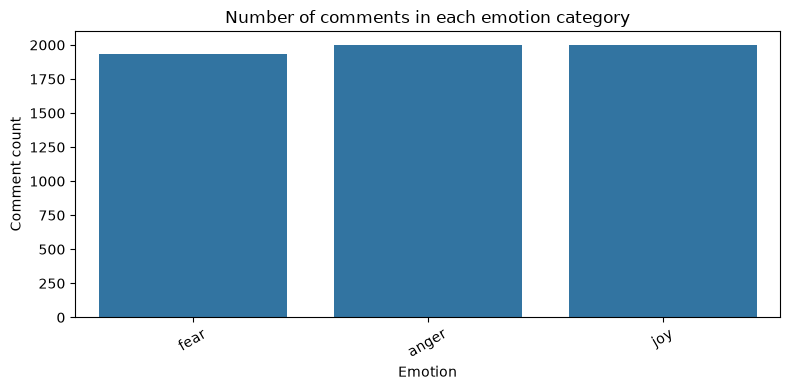

In [6]:
display(data["Emotion"].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=data, x="Emotion")
plt.title("Number of comments in each emotion category")
plt.xlabel("Emotion")
plt.ylabel("Comment count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Prepare the text and label columns

Remove records that do not have a comment or emotion label. Remove duplicate records as well.

In [7]:
data = data.dropna(subset=["Comment", "Emotion"]).drop_duplicates().copy()
data["Comment"] = data["Comment"].astype(str)
data["Emotion"] = data["Emotion"].astype(str)

print("Dataset size after preparation:", data.shape)

Dataset size after preparation: (5937, 2)


## 5. Clean the text

Convert comments to lowercase, remove characters other than English letters and whitespace, and normalize repeated spaces.

In [8]:
def preprocess_sentence(sentence):
    sentence = sentence.lower()
    sentence = re.sub(r"[^a-z\s]", " ", sentence)
    sentence = re.sub(r"\s+", " ", sentence)
    return sentence.strip()

data["Clean_Text"] = data["Comment"].apply(preprocess_sentence)
data[["Comment", "Clean_Text"]].head()

,Comment,Clean_Text
0,i seriously hate one subject to death but now i feel reluctant to drop it,i seriously hate one subject to death but now i feel reluctant to drop it
1,im so full of life i feel appalled,im so full of life i feel appalled
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,ive been really angry with r and i feel like an idiot for trusting him in the first place
4,i feel suspicious if there is no one outside like the rapture has happened or something,i feel suspicious if there is no one outside like the rapture has happened or something


## 6. Tokenize the comments

Tokenization divides each cleaned comment into individual word tokens.

In [9]:
data["Word_Tokens"] = data["Clean_Text"].apply(lambda sentence: sentence.split())
data[["Clean_Text", "Word_Tokens"]].head()

,Clean_Text,Word_Tokens
0,i seriously hate one subject to death but now i feel reluctant to drop it,"[i, seriously, hate, one, subject, to, death, but, now, i, feel, reluctant, to, drop, it]"
1,im so full of life i feel appalled,"[im, so, full, of, life, i, feel, appalled]"
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,"[i, sit, here, to, write, i, start, to, dig, out, my, feelings, and, i, think, that, i, am, afraid, to, accept, the,..."
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,"[ive, been, really, angry, with, r, and, i, feel, like, an, idiot, for, trusting, him, in, the, first, place]"
4,i feel suspicious if there is no one outside like the rapture has happened or something,"[i, feel, suspicious, if, there, is, no, one, outside, like, the, rapture, has, happened, or, something]"


## 7. Remove stopwords

Common English stopwords are removed using scikit-learn's built-in stopword collection.

In [10]:
english_stopwords = set(ENGLISH_STOP_WORDS)

def filter_stopwords(words):
    useful_words = [word for word in words if word not in english_stopwords]
    return " ".join(useful_words)

data["Model_Text"] = data["Word_Tokens"].apply(filter_stopwords)
data[["Clean_Text", "Model_Text"]].head()

,Clean_Text,Model_Text
0,i seriously hate one subject to death but now i feel reluctant to drop it,seriously hate subject death feel reluctant drop
1,im so full of life i feel appalled,im life feel appalled
2,i sit here to write i start to dig out my feelings and i think that i am afraid to accept the possibility that he mi...,sit write start dig feelings think afraid accept possibility make
3,ive been really angry with r and i feel like an idiot for trusting him in the first place,ive really angry r feel like idiot trusting place
4,i feel suspicious if there is no one outside like the rapture has happened or something,feel suspicious outside like rapture happened


### Summary of preprocessing

- **Cleaning:** lowercase conversion and removal of punctuation, digits and symbols.
- **Tokenization:** splitting each comment into words.
- **Stopword removal:** filtering common English words.

These operations prepare the text for feature extraction and reduce some unnecessary variation in the input.

## 8. Define features and target

The processed comment is the input feature, and the emotion column is the target label.

In [11]:
text_features = data["Model_Text"]
emotion_labels = data["Emotion"]

print("Total text samples:", len(text_features))
print("\nEmotion categories:")
print(emotion_labels.value_counts())

Total text samples: 5937

Emotion categories:
Emotion
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64


## 9. Split into training and testing data

Use a stratified split so that the emotion-category proportions are maintained in both sets.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    text_features,
    emotion_labels,
    test_size=0.20,
    random_state=42,
    stratify=emotion_labels
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 4749
Testing records: 1188


## 10. Convert text into TF-IDF features

TF-IDF represents words numerically. It gives more weight to terms that are informative in a comment and less weight to terms that occur widely. Fit the vectorizer on training data only to avoid test-data leakage.

In [13]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train_vectors = vectorizer.fit_transform(X_train)
X_test_vectors = vectorizer.transform(X_test)

print("Training matrix:", X_train_vectors.shape)
print("Testing matrix:", X_test_vectors.shape)

Training matrix: (4749, 5000)
Testing matrix: (1188, 5000)


## 11. Train Model 1 – Naive Bayes

Multinomial Naive Bayes is commonly used for text classification. Train it using the TF-IDF training features.

In [14]:
naive_bayes = MultinomialNB()
naive_bayes.fit(X_train_vectors, y_train)

nb_predictions = naive_bayes.predict(X_test_vectors)

nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_f1 = f1_score(y_test, nb_predictions, average="weighted")

print("Naive Bayes accuracy:", nb_accuracy)
print("Naive Bayes weighted F1-score:", nb_f1)

Naive Bayes accuracy: 0.9040404040404041
Naive Bayes weighted F1-score: 0.9041229159858839


## 12. Train Model 2 – Support Vector Machine

A linear SVM learns a separating boundary between emotion categories. It is often effective with sparse, high-dimensional text features.

In [15]:
svm_classifier = LinearSVC()
svm_classifier.fit(X_train_vectors, y_train)

svm_predictions = svm_classifier.predict(X_test_vectors)

svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions, average="weighted")

print("SVM accuracy:", svm_accuracy)
print("SVM weighted F1-score:", svm_f1)

SVM accuracy: 0.9436026936026936
SVM weighted F1-score: 0.943575873644522


## 13. Classification reports

The classification report shows precision, recall and F1-score for each emotion class, along with averages.

In [16]:
print("NAIVE BAYES REPORT")
print(classification_report(y_test, nb_predictions))

NAIVE BAYES REPORT
              precision    recall  f1-score   support

       anger       0.90      0.91      0.90       400
        fear       0.88      0.92      0.90       388
         joy       0.94      0.88      0.91       400

    accuracy                           0.90      1188
   macro avg       0.90      0.90      0.90      1188
weighted avg       0.91      0.90      0.90      1188



In [17]:
print("SUPPORT VECTOR MACHINE REPORT")
print(classification_report(y_test, svm_predictions))

SUPPORT VECTOR MACHINE REPORT
              precision    recall  f1-score   support

       anger       0.95      0.93      0.94       400
        fear       0.94      0.95      0.94       388
         joy       0.94      0.96      0.95       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



## 14. Compare the models

Compare accuracy and weighted F1-score on the same test set.

In [18]:
comparison = pd.DataFrame({
    "Classifier": ["Naive Bayes", "Support Vector Machine"],
    "Accuracy": [nb_accuracy, svm_accuracy],
    "Weighted F1-score": [nb_f1, svm_f1]
})

display(comparison)

,Classifier,Accuracy,Weighted F1-score
0,Naive Bayes,0.904040,0.904123
1,Support Vector Machine,0.943603,0.943576


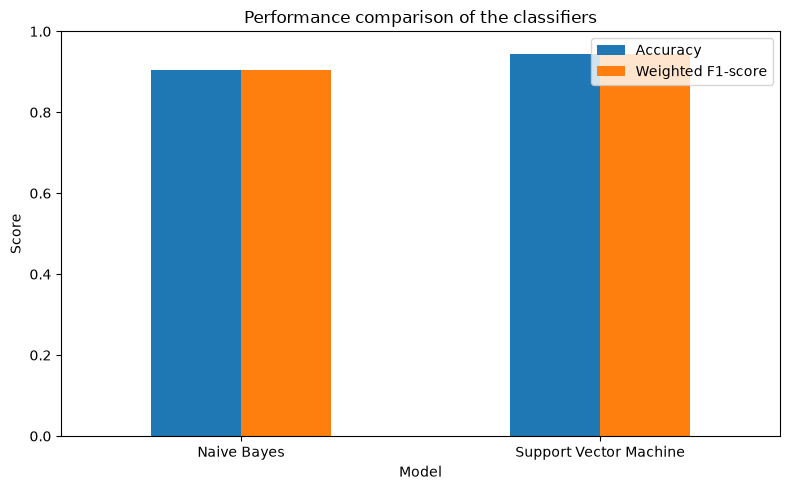

In [19]:
comparison.set_index("Classifier").plot(
    kind="bar", figsize=(8, 5), ylim=(0, 1)
)
plt.title("Performance comparison of the classifiers")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 15. Confusion matrices

A confusion matrix compares actual labels with predicted labels. The diagonal cells represent correct predictions.

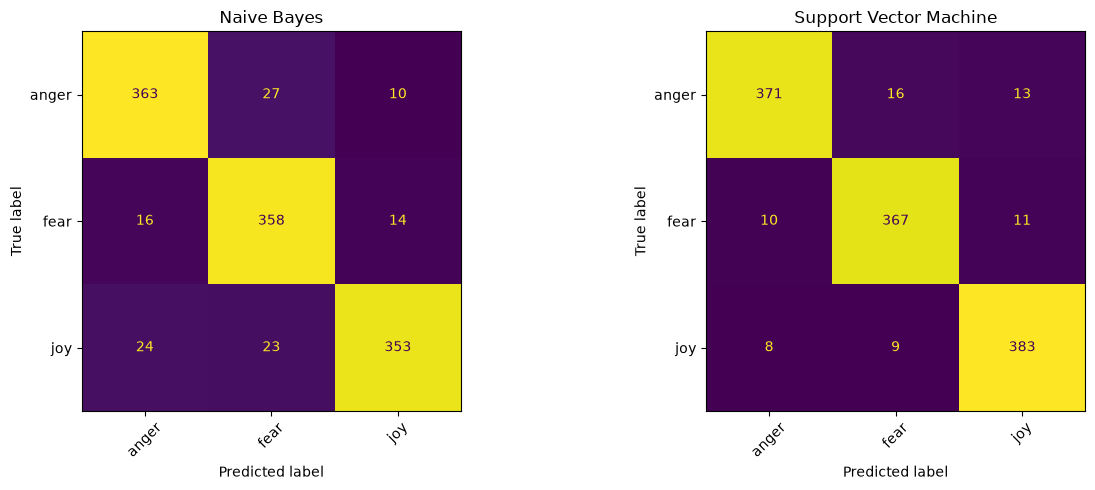

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, nb_predictions, ax=axes[0], colorbar=False, xticks_rotation=45
)
axes[0].set_title("Naive Bayes")

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_predictions, ax=axes[1], colorbar=False, xticks_rotation=45
)
axes[1].set_title("Support Vector Machine")

plt.tight_layout()
plt.show()

## 16. Discussion

Naive Bayes is a probabilistic classifier based on Bayes' theorem. It is computationally efficient and is a useful baseline for text classification.

Support Vector Machine is a supervised learning method that identifies a decision boundary between classes. A linear SVM can work well with TF-IDF text features.

Accuracy measures the proportion of correctly classified comments. The weighted F1-score combines precision and recall while accounting for the number of samples in each class. Compare the values printed above to decide which classifier performed better on this test split.

## 17. Conclusion

This notebook applies machine learning techniques to classify emotions from text comments. The comments are cleaned, tokenized and filtered to remove common stopwords. TF-IDF is then used to convert text into numerical features. Multinomial Naive Bayes and a linear Support Vector Machine are trained and evaluated using accuracy, weighted F1-score, classification reports and confusion matrices. The comparison indicates which of the two models performs better on the selected test data.